In [18]:
#import and configuration
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

from sklearn.metrics import (
    classification_report,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

PROJECT_DIR = Path(r"D:\Pradeep Pandey\Nexvia Technology  Intership\Project 1")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CHECKPOINT_PATH = PROJECT_DIR / "outputs/models/densenet121_finetuned.pth"
SPLIT_DIR = PROJECT_DIR / "processed"
IMAGE_DIR = PROJECT_DIR / "data/sample/images"

OUTPUT_DIR = PROJECT_DIR / "outputs/evaluation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Device:", device)
print("Evaluation setup ready!")

Device: cpu
Evaluation setup ready!


In [19]:
#loading fine tuned model 
checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)

disease_classes = checkpoint["disease_classes"]

model = models.densenet121(weights=None)
model.classifier = nn.Linear(1024, len(disease_classes))

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

print("Fine-tuned DenseNet121 loaded!")
print("Number of classes:", len(disease_classes))

Fine-tuned DenseNet121 loaded!
Number of classes: 14


In [20]:
#test cases 
test_df = pd.read_csv(SPLIT_DIR / "test.csv")

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class ChestXrayDataset(Dataset):
    def __init__(self, df, image_dir, classes, transform):
        self.df = df.reset_index(drop=True)
        self.image_dir = image_dir
        self.classes = classes
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]

        image = Image.open(
            self.image_dir / row["Image Index"]
        ).convert("RGB")

        labels = torch.tensor(
            row[self.classes].to_numpy(dtype=np.float32)
        )

        return self.transform(image), labels


test_dataset = ChestXrayDataset(
    test_df, IMAGE_DIR, disease_classes, eval_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

print("Test images:", len(test_dataset))
print("Test batches:", len(test_loader))

Test images: 554
Test batches: 35


In [22]:
# generating prediction 
all_labels = []
all_probs = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        probabilities = torch.sigmoid(outputs)

        all_labels.append(labels.numpy())
        all_probs.append(probabilities.cpu().numpy())

y_true = np.concatenate(all_labels)
y_prob = np.concatenate(all_probs)

print("Actual labels:", y_true.shape)
print("Predicted probabilities:", y_prob.shape)
print("Predictions generated successfully!")

Actual labels: (554, 14)
Predicted probabilities: (554, 14)
Predictions generated successfully!


In [26]:
print("Positive predictions per disease:\n")

for i, disease in enumerate(disease_classes):
    print(f"{disease:20} {y_pred[:, i].sum()}")

print("\nTotal positive predictions:", y_pred.sum())
print("Threshold:", THRESHOLD)

Test Ranking Performance:

Atelectasis          ROC-AUC: 0.649 | AP: 0.117
Cardiomegaly         ROC-AUC: 0.495 | AP: 0.023
Effusion             ROC-AUC: 0.746 | AP: 0.289
Infiltration         ROC-AUC: 0.586 | AP: 0.216
Mass                 ROC-AUC: 0.566 | AP: 0.158
Nodule               ROC-AUC: 0.602 | AP: 0.068
Pneumonia            ROC-AUC: 0.812 | AP: 0.077
Pneumothorax         ROC-AUC: 0.626 | AP: 0.062
Consolidation        ROC-AUC: 0.745 | AP: 0.113
Edema                ROC-AUC: 0.828 | AP: 0.128
Emphysema            ROC-AUC: 0.767 | AP: 0.101
Fibrosis             ROC-AUC: 0.334 | AP: 0.009
Pleural_Thickening   ROC-AUC: 0.632 | AP: 0.072
Hernia               ROC-AUC: 0.610 | AP: 0.007

Macro ROC-AUC: 0.6426
Macro Average Precision: 0.1028


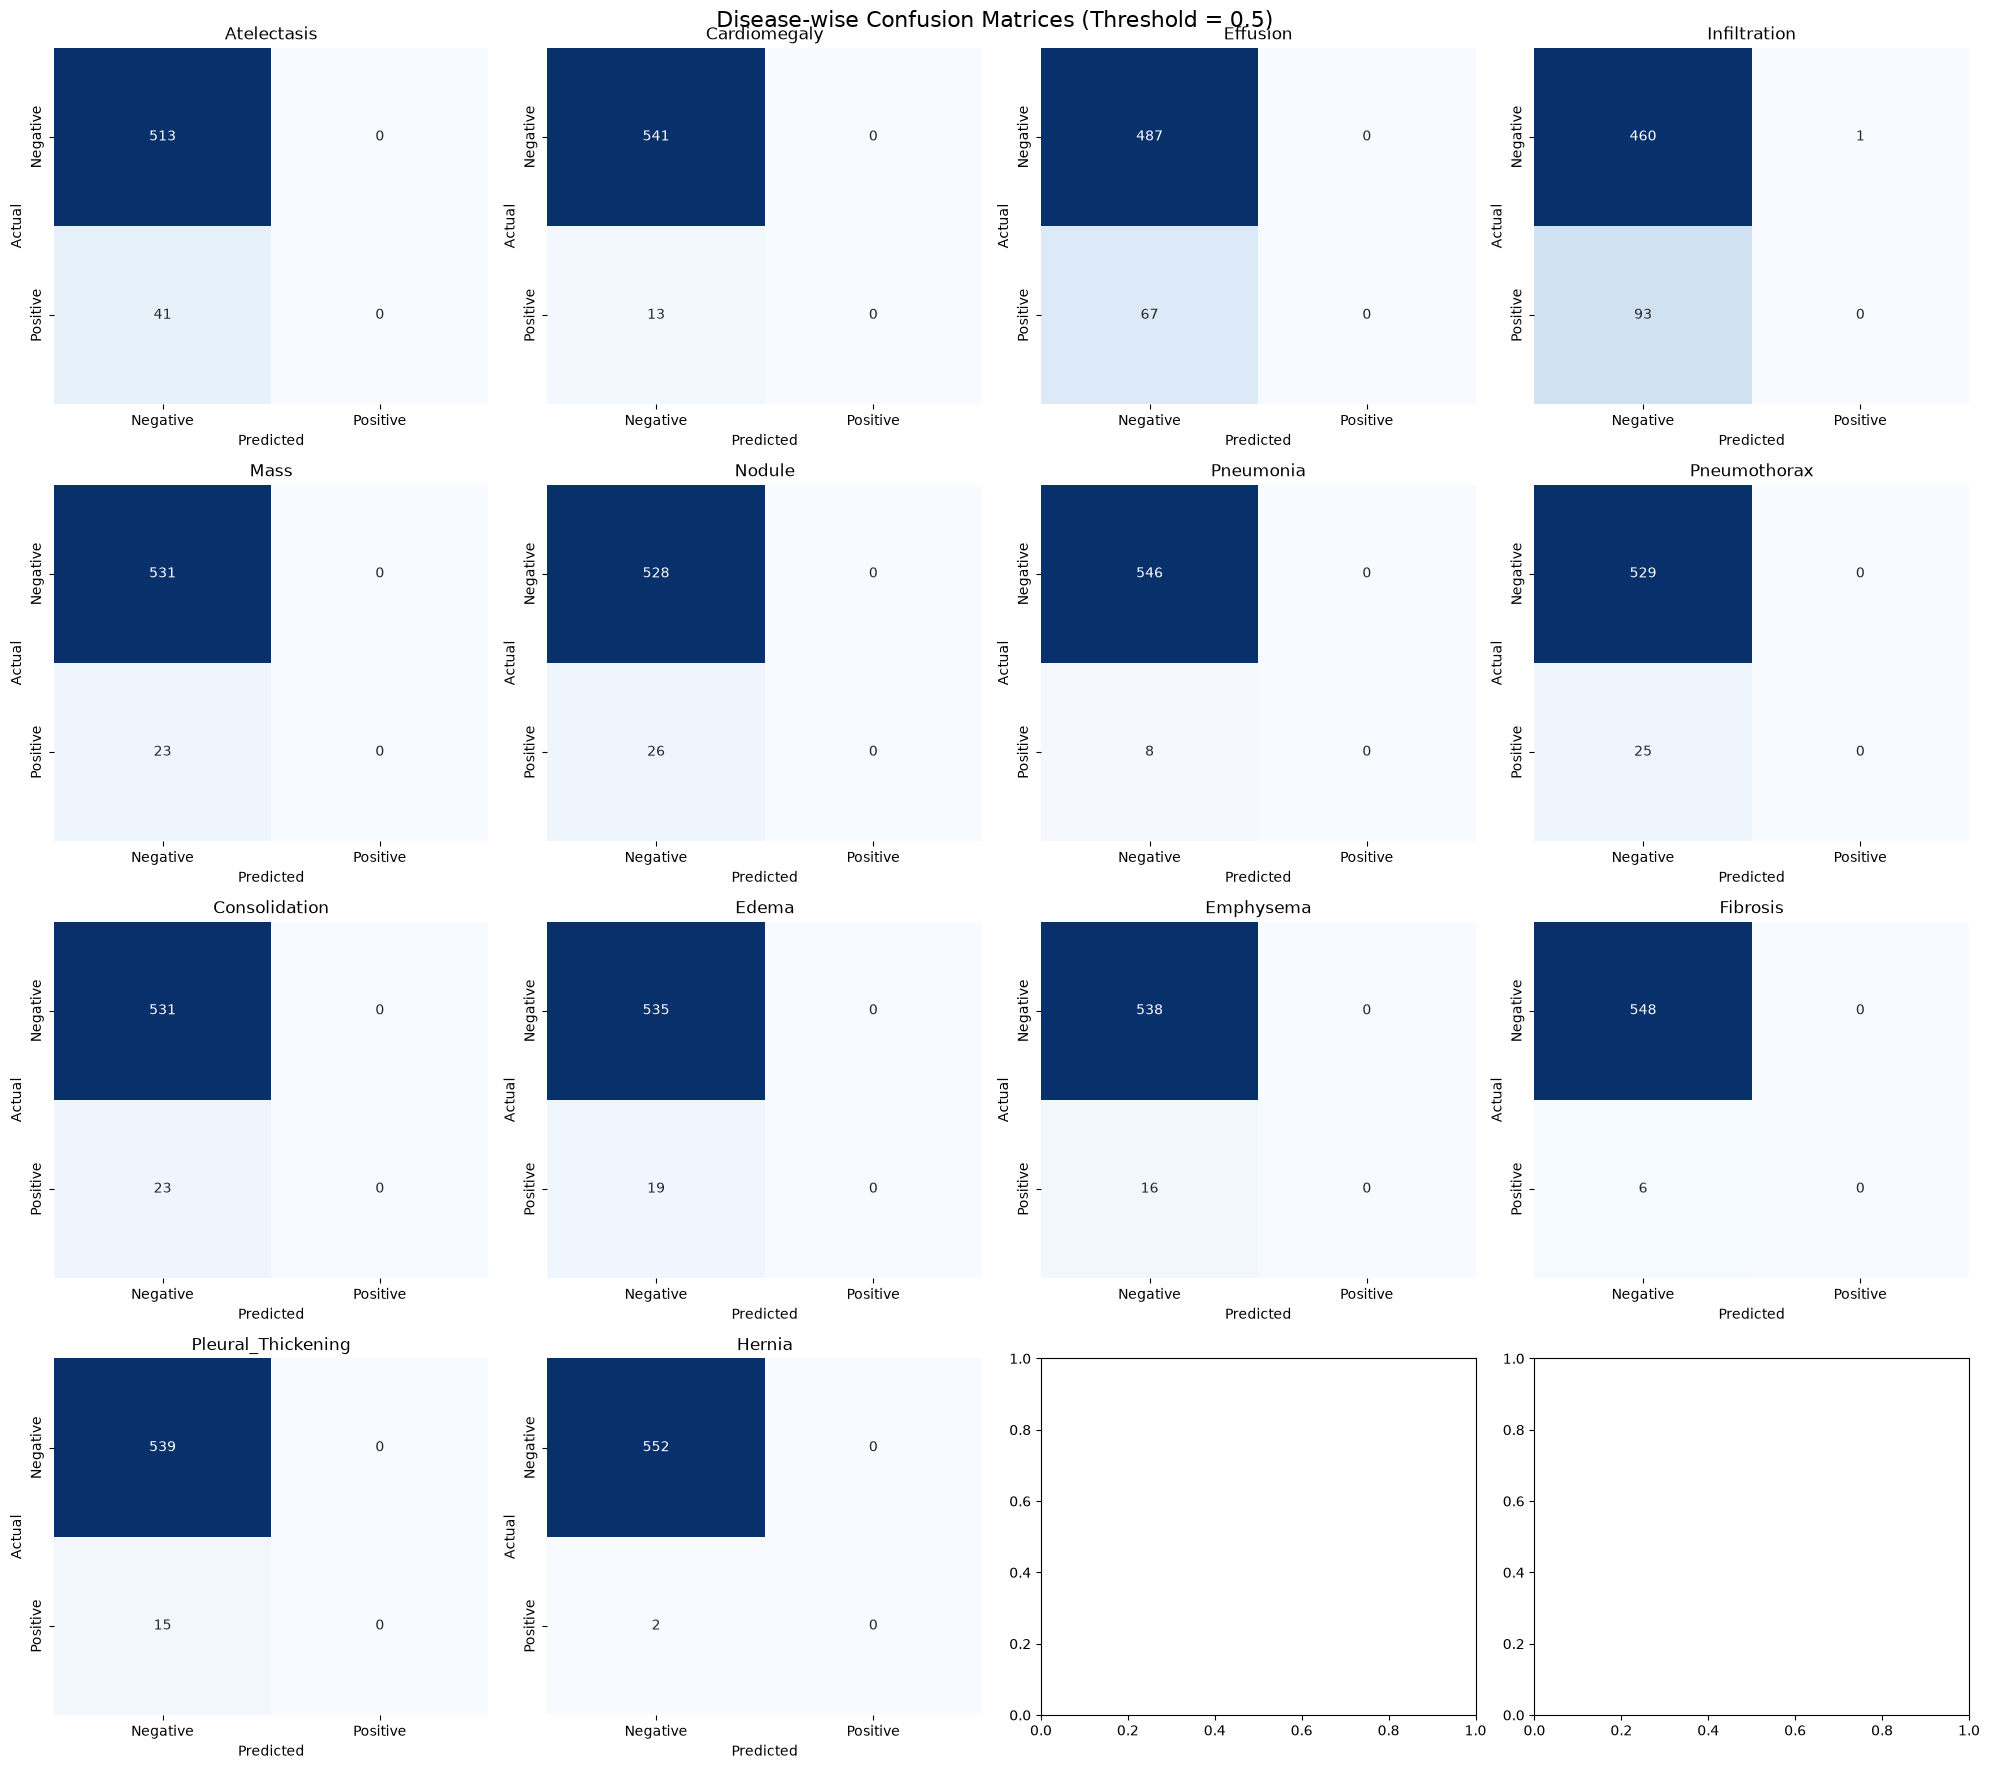

In [27]:
#confusion metric
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

THRESHOLD = 0.5

# Generate predictions
y_pred = (y_prob >= THRESHOLD).astype(int)

# Plot confusion matrices
fig, axes = plt.subplots(4, 4, figsize=(20, 18))

for i, disease in enumerate(disease_classes):

    cm = confusion_matrix(
        y_true[:, i],
        y_pred[:, i],
        labels=[0, 1]
    )

    ax = axes[i // 4, i % 4]

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Negative", "Positive"],
        yticklabels=["Negative", "Positive"],
        ax=ax
    )

    ax.set_title(disease)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.suptitle(
    "Disease-wise Confusion Matrices (Threshold = 0.5)",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [29]:
# saving evaluation metric 
import pandas as pd
from sklearn.metrics import (
    precision_recall_fscore_support,
    confusion_matrix
)


metrics_dir = PROJECT_DIR / "outputs" / "metrics"
metrics_dir.mkdir(parents=True, exist_ok=True)


THRESHOLD = 0.5
y_pred = (y_prob >= THRESHOLD).astype(int)

results = []

for i, disease in enumerate(disease_classes):

   
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true[:, i],
        y_pred[:, i],
        average="binary",
        zero_division=0
    )

   
    tn, fp, fn, tp = confusion_matrix(
        y_true[:, i],
        y_pred[:, i],
        labels=[0, 1]
    ).ravel()

    
    results.append({
        "Disease": disease,
        "ROC_AUC": auc_scores[i],
        "Average_Precision": ap_scores[i],
        "Precision": precision,
        "Recall": recall,
        "F1_Score": f1,
        "Support": int(y_true[:, i].sum()),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })


metrics_df = pd.DataFrame(results)


metrics_path = metrics_dir / "test_evaluation_metrics.csv"
metrics_df.to_csv(metrics_path, index=False)


macro_roc_auc = metrics_df["ROC_AUC"].mean()
macro_ap = metrics_df["Average_Precision"].mean()
macro_precision = metrics_df["Precision"].mean()
macro_recall = metrics_df["Recall"].mean()
macro_f1 = metrics_df["F1_Score"].mean()

print("TEST EVALUATION SUMMARY")
print("-" * 45)
print(f"Threshold:              {THRESHOLD}")
print(f"Macro ROC-AUC:          {macro_roc_auc:.4f}")
print(f"Macro Average Precision:{macro_ap:.4f}")
print(f"Macro Precision:        {macro_precision:.4f}")
print(f"Macro Recall:           {macro_recall:.4f}")
print(f"Macro F1-Score:         {macro_f1:.4f}")
print(f"Total Actual Positives: {int(y_true.sum())}")
print(f"Total Predicted Positives: {int(y_pred.sum())}")

print("\nDisease-wise Evaluation Metrics:")
display(metrics_df)

print("\nMetrics saved successfully!")
print(metrics_path)

TEST EVALUATION SUMMARY
---------------------------------------------
Threshold:              0.5
Macro ROC-AUC:          0.6426
Macro Average Precision:0.1028
Macro Precision:        0.0000
Macro Recall:           0.0000
Macro F1-Score:         0.0000
Total Actual Positives: 377
Total Predicted Positives: 1

Disease-wise Evaluation Metrics:


,Disease,ROC_AUC,Average_Precision,Precision,Recall,F1_Score,Support,TN,FP,FN,TP
0,Atelectasis,0.649170,0.116921,0.0,0.0,0.0,41,513,0,41,0
1,Cardiomegaly,0.495379,0.023050,0.0,0.0,0.0,13,541,0,13,0
2,Effusion,0.745533,0.288724,0.0,0.0,0.0,67,487,0,67,0
3,Infiltration,0.585707,0.215870,0.0,0.0,0.0,93,460,1,93,0
4,Mass,0.565627,0.157704,0.0,0.0,0.0,23,531,0,23,0
5,Nodule,0.602054,0.068206,0.0,0.0,0.0,26,528,0,26,0
6,Pneumonia,0.812271,0.077492,0.0,0.0,0.0,8,546,0,8,0
7,Pneumothorax,0.625709,0.062358,0.0,0.0,0.0,25,529,0,25,0
8,Consolidation,0.744698,0.112938,0.0,0.0,0.0,23,531,0,23,0
9,Edema,0.827644,0.128154,0.0,0.0,0.0,19,535,0,19,0



Metrics saved successfully!
D:\Pradeep Pandey\Nexvia Technology  Intership\Project 1\outputs\metrics\test_evaluation_metrics.csv


In [30]:
#saving confusion matrix plot
confusion_matrix_path = metrics_dir / "confusion_matrices.png"

fig.savefig(
    confusion_matrix_path,
    dpi=300,
    bbox_inches="tight"
)

print("Confusion matrices saved successfully!")
print(confusion_matrix_path)

Confusion matrices saved successfully!
D:\Pradeep Pandey\Nexvia Technology  Intership\Project 1\outputs\metrics\confusion_matrices.png


In [15]:
model.load_state_dict(finetuned["model_state_dict"])
model.eval()

print("Fine-tuned checkpoint loaded successfully!")

Fine-tuned checkpoint loaded successfully!
